In [ ]:
import os
import random
import numpy as np
import cv2
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import fnmatch

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#! unzip -o /content/drive/MyDrive/faces.zip

Question 1 - Implementation of `loadImages()` function:

In [ ]:
dataset_path = "/content/faces"

In [ ]:
def init_dict():
    dict_ = {}
    dict_['Set_1'] = list(range(1, 8))
    dict_['Set_2'] = list(range(8, 20))
    dict_['Set_3'] = list(range(20, 32))
    dict_['Set_4'] = list(range(32, 46))
    dict_['Set_5'] = list(range(46, 65))
    return dict_

In [ ]:
sets_dict = init_dict()

In [ ]:
def loadImages(dataset_path,key):
    x = []
    y = []
    for i in sets_dict[key]:
        file_name = f'person*_{i:02d}.png'

        for file_ in os.listdir(dataset_path):
            if fnmatch.fnmatch(file_, file_name):
                file_path = os.path.join(dataset_path, file_)
                label = int(file_.split('_')[0].replace('person', ''))

                image = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
                img_to_vec = image.flatten()
                x.append(img_to_vec)
                y.append(label)

    return np.array(x).transpose(), np.array(y).transpose()  #every image (1d vector of size 50x50) is a column in the matrix

We divide the samples into sets and acquire the corresponding labes.

In [ ]:
keys = ['Set_1','Set_2','Set_3','Set_4','Set_5']
X = {}
Y = {}
X_dataset = {}
for i in keys:          #Load all sets
  X[i], Y[i] = loadImages(dataset_path,i)      #Data matrix X contains images as column vectors
  X_dataset[i] = X[i].copy()

Question 2 - Training Eigenfaces method using Set_1 and d=30 principal components:

Implementing our own method that performs PCA:
1. Given the data matrix $X$ we compute the covariance matrix $XX^T$
2. We use `np.linalg.eigh()` to find the eigenvectors of $XX^T$ and their corresponding eigenvalues
3. We sort the eignenvalues and their eigenvectors in descending order and we keep the first k ones. These are the top k principal components (eigenvectors)

- To project our data matrix $X$ onto the k dimensional space we call method `transform()`
- To reconstruct our matrix $X$ using the principal components matrix we call method `inverse_transform()`

In [ ]:
#PCA operates on data matrices X where each column represents a data sample.
#The data samples inside X are already normalized and centered.
class CustomPCA:
    def __init__(self, k_components):
        self.k_components = k_components
        self.top_k_eigenvectors = None

    def fit(self, X):
        #Compute the covariance matrix of the data
        cov_matrix = (X @ X.T) / X.T.shape[0]

        #Compute the eigenvectors and eigenvalues of covarinace matrix
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        # Sort eigenvalues and their corresponding eigenvectors by descending order
        sorted_indices = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[sorted_indices]
        eigenvectors = eigenvectors[:, sorted_indices]

        # Keep the top k components (eigenvectors)
        self.top_k_eigenvectors = eigenvectors[:, :self.k_components]
        return self

    def transform(self, X):
        # Project data onto the k dimensional basis formed by the eigenvectors
        return self.top_k_eigenvectors.T @ X

    def inverse_transform(self, X_projected):
        # Reconstruct original data from k dimensional space of eigenvectors
        return self.top_k_eigenvectors @ X_projected


Before we start training we need to preprocess the data. Particularly, we need to center and scale the data. For each of the 2500 dimensions of our images, we subtract the mean $μ$ and divide by the standard deviation $σ$.

In [ ]:
#Subtracting the mean and dividing by the standard deviation
def ImagePreprocessing(X):
    scaler = StandardScaler()
    X = scaler.fit_transform(X)
    return X.T,scaler

In [ ]:
def knnClassifier(k,X,Y):
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(X,Y)
  return knn

In [ ]:
def Eigenfaces_method(d_components,X,Y):
    pca = CustomPCA(k_components=d_components).fit(X)                 #learns the k-components
    X_projected_to_k_dim = pca.transform(X)               #projects the original data to the eigenspace
    knn = knnClassifier(1,X_projected_to_k_dim.T,Y)       #using the k-dimensional data for training
    return pca, X_projected_to_k_dim, knn

In [ ]:
#Data preprocessing
scaler = {}
for i in keys:
  X[i],scaler[i] = ImagePreprocessing(X[i].T)

In [ ]:
#Training Eigenfaces with d=30
d = 30
pca_components_30, X_projected, knn_model = Eigenfaces_method(d,X['Set_1'],Y['Set_1'])

In [ ]:
#Reconstruction of the original data using the k=30 components
X_reconstructed = pca_components_30.inverse_transform(X_projected)

In [ ]:
#Choose a random image from Set_1
random_index = random.randint(0, X['Set_1'].T.shape[0] - 1)

We compare the original image with the one that we reconstructed using the top 30 components extracted by PCA.

In [ ]:
def plot_image(image,title=""):
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.title(title)

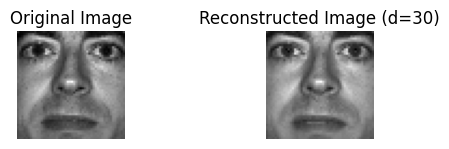

In [ ]:
original_image = X_dataset['Set_1'][:,random_index]
original_image = original_image.reshape(50, 50)

plt.figure(figsize=(6, 1.6))
plt.subplot(1, 2, 1)
plot_image(original_image,title="Original Image")
plt.subplot(1, 2, 2)

scaled_back_x = scaler['Set_1'].inverse_transform(X_reconstructed.T)
reconstructed_image = scaled_back_x[random_index]
reconstructed_image = reconstructed_image.reshape(50,50)

plot_image(reconstructed_image,title=f"Reconstructed Image (d={d})")
plt.tight_layout()
plt.show()

Using top 30 principal components (d=30) seems to be enough to accurately reconstruct an image of Set 1. This is because the higher the number of principal components, the higher the level of variance (information) captured from the original data.

Question 3 - Training Eigenfaces method, varying d inside [20,200]:

In [ ]:
def plot_mean_error_var_d(x_axis,y_axis):
  plt.figure(figsize=(6, 4))
  plt.plot(x_axis, y_axis, marker='o')
  plt.xlabel("Number of Principal Components (d)")
  plt.ylabel("Mean Reconstruction Error")
  plt.show()

We will train Eigenfaces again using Set 1. We are choosing 10 different values for d, from inside the interval [2,200].

In [ ]:
#Choosing values for d principal components inside interval [2,200]
d_values = np.linspace(2, 200, 10, dtype=int)
d_values

array([  2,  24,  46,  68,  90, 112, 134, 156, 178, 200])

In [ ]:
projected_data = {}
reconstructed_data = {}
trained_models = {}
pca_models = {}
for i in d_values:
  d = i
  d_components, X_projected, classification_model = Eigenfaces_method(d,X['Set_1'],Y['Set_1'])
  X_reconstructed = d_components.inverse_transform(X_projected)

  projected_data[d] = X_projected
  reconstructed_data[d] = X_reconstructed
  trained_models[d] = classification_model
  pca_models[d] = d_components

For every value of $d$, we compute the mean error value where $e_i = \| X_i - X_i' \|_2$ is the error for the $i$-th image. $X_i$ is the original image in the dataset and $X_i'$ is the reconstructed one.


Mean error value for d=2 is 1155.1237625831754
Mean error value for d=24 is 248.44413122259
Mean error value for d=46 is 93.70382520930123
Mean error value for d=68 is 7.555023685781628
Mean error value for d=90 is 1.0652859264848399e-11
Mean error value for d=112 is 1.0415261057852543e-11
Mean error value for d=134 is 1.0413548948455038e-11
Mean error value for d=156 is 1.0411692057798829e-11
Mean error value for d=178 is 1.0408980565278288e-11
Mean error value for d=200 is 1.0406598215319314e-11


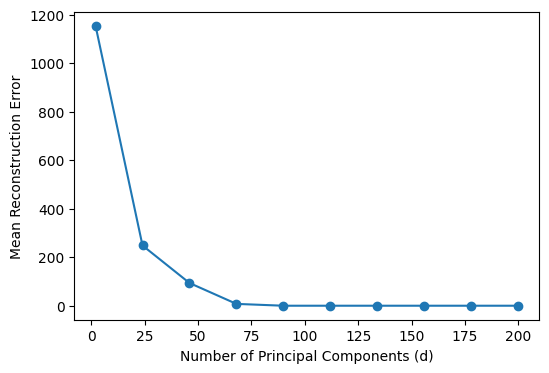

In [ ]:
mean_errors = []
samples_num = X_dataset['Set_1'].shape[1]
original_xs = X_dataset['Set_1'].T
for i in d_values:
    reconstructed_imgs = reconstructed_data[i].T
    reconstructed_img = scaler['Set_1'].inverse_transform(reconstructed_imgs)
    errors = []
    for j in range(samples_num):
        original_image = original_xs[j]
        reconstructed_image = reconstructed_img[j]

        error = np.linalg.norm(original_image - reconstructed_image)
        errors.append(error)

    mean_error = np.mean(errors)
    print(f"Mean error value for d={i} is {mean_error}")
    mean_errors.append(mean_error)

plot_mean_error_var_d(d_values,mean_errors)

From the data above we observe that as the number of principal components, d, increases the mean reconstruction error decreases. This is logical, since the number of principal components represents the number of directions of the highest variance in the data. As d increases, we capture more directions of high variance in our data so we can represent it more accurately.

As seen from the plot, when $d$ is close to 70, the mean error is very close to zero. When d > 70, the mean error stops decreasing and remains roughly constant. This means that there is no point in using a value of $d$ higher than 70 to train our model, since the mean error does not improve further.

From a mathematical persepective the latter observation can be explained as follows:

 Set 1 contains 70 samples of 2500 dimensions each.
For the covarianvce matrix $Σ$ and the corresponding eigenvectors $W$ we have $$ ΣW=ΛW $$ where $Λ$ is a diagonal matrix with the eigenvalues.  
We have that:
$$rank(Σ)=rank(X^TX)\leq min(rank(X),rank(X^T))=min(70,70)=70 $$  
We know that the rank of $Σ$ is the same as the number of its non-zero eigenvalues.
This means that we can find at most 70 non-zero principal components (eigenvalues) for covariance matrix $Σ$. This means that there is no variance in tha data to capture more than the variance that is captured using 70 principal components. This is essentially why the mean reconstruction error does not improve when d>70.

Question 4 - Plotting 9 principal components:

We are plotting the top 9 eigenvectors we get from training Eigenfaces method with Set 1. We choose arbitrarily, the top 9 eigenvectors when d=30.

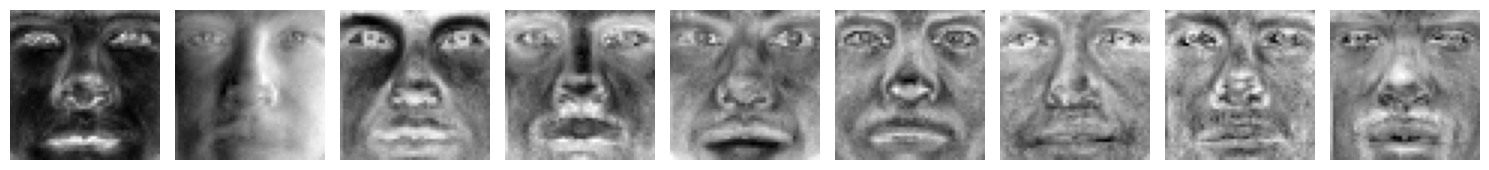

In [ ]:
plt.figure(figsize=(15, 3))
for i in range(9):
    plt.subplot(1, 9, i+1)
    plot_image(pca_components_30.top_k_eigenvectors[:,i].reshape(50, 50))
plt.tight_layout()
plt.show()

As we can see the top 9 eigenvectors seem to capture certain patterns in our data. The first components seem to be related to the illumination angle of the images, whereas the next ones capture patterns of different characteristics of the human face like nose and eyes.

Question 5 - Classification:

To perfrom our classification we first project the test set in the eigenspace. We then make predictions within this eigenspace.

In [ ]:
from sklearn.metrics import accuracy_score
scores_dict = {d: {} for d in d_values}

for d in d_values:
  classifier = trained_models[d]
  pca = pca_models[d]
  for test_set in keys:

    X_test = pca.transform(X[test_set])         #Project test data to eigenspace
    Y_pred = classifier.predict(X_test.T)       #Make predictions in the eigenspace
    score = accuracy_score(Y_pred, Y[test_set])

    scores_dict[d][test_set] = score


In [ ]:
df_scores = pd.DataFrame(scores_dict).T
df_scores = df_scores.round(3)
df_scores = df_scores.reset_index()
df_scores = df_scores.rename(columns={'index': 'd'})

print("📊 Classification Accuracy Table:\n")
print(df_scores)

📊 Classification Accuracy Table:

     d  Set_1  Set_2  Set_3  Set_4  Set_5
0    2    1.0  0.233  0.183  0.121  0.142
1   24    1.0  0.967  0.858  0.400  0.216
2   46    1.0  0.967  0.867  0.457  0.242
3   68    1.0  0.967  0.867  0.464  0.242
4   90    1.0  0.967  0.867  0.464  0.242
5  112    1.0  0.967  0.867  0.464  0.242
6  134    1.0  0.967  0.867  0.464  0.242
7  156    1.0  0.967  0.867  0.464  0.242
8  178    1.0  0.967  0.867  0.464  0.242
9  200    1.0  0.967  0.867  0.464  0.242


For each set, we plot the accuracy with respect to d (the number of principal components used).

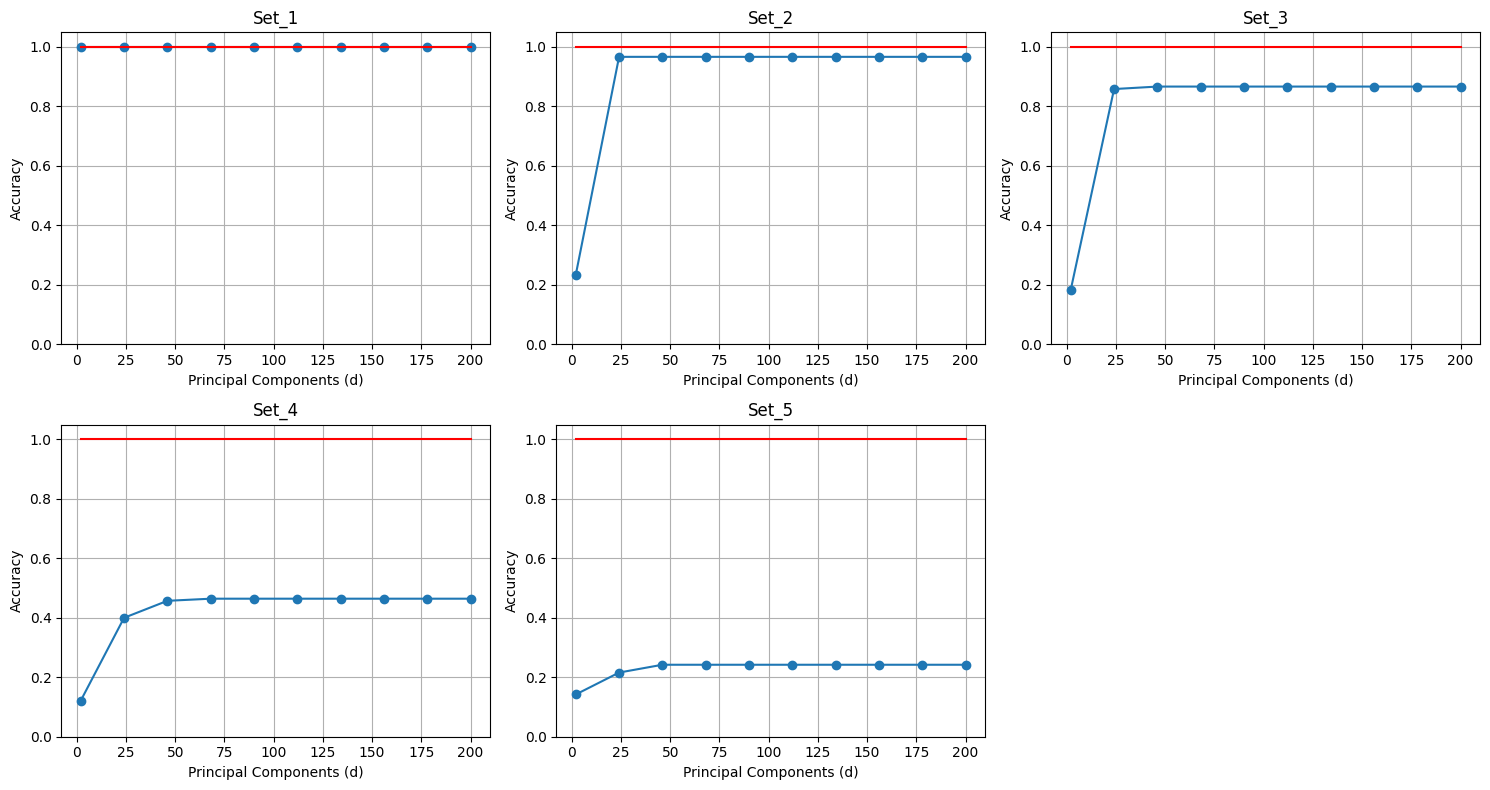

In [ ]:
import math
plots_per_row = 3
total_plots = len(keys)
n_rows = math.ceil(total_plots / plots_per_row)

fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(5 * plots_per_row, 4 * n_rows))
axes = axes.flatten()

set1_scores = [scores_dict[d]['Set_1'] for d in d_values]

for idx, test_set in enumerate(keys):
    ax = axes[idx]
    scores = [scores_dict[d][test_set] for d in d_values]
    ax.plot(d_values, scores, marker='o', color='tab:blue')
    ax.plot(d_values, set1_scores, color='red')
    ax.set_title(f'{test_set}')
    ax.set_xlabel('Principal Components (d)')
    ax.set_ylabel('Accuracy')
    ax.set_ylim(0, 1.05)
    ax.grid(True)

for j in range(len(keys), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

5a. For Set 1, we get an accuracy of 1, which is expected since it is our training set.
For Set 2, we also get an accuracy that is very close to 1. This high accuracy is reached when d = 25. When d > 25, we observe no further increase in accuracy. This can be explained by the fact that the images of Sets 1 and 2 are taken under the same lighting conditions. This means that the main features captured during training on Set 1 are similar to the main features of Set 2, and thus we get a very high accuracy. High accuracy for d = 25 means that the number of components needed to accurately capture the patterns of the images is close to 25. The value of d is small because the data samples in the two datasets (1 and 2) are very similar, so the directions of variance in Set 1 are similar to those of Set 2, and thus few components are needed to sufficiently represent them.

To achieve the highest possible accuracy on Sets 3, 4, and 5, we need more components (a value of d higher than 25). Even then, the highest accuracy achieved for these sets remains quite low. This is likely because Sets 3, 4, and 5 contain darker images taken under a different illumination angle. As a result, the main patterns in these Sets differ from those captured during training on Set 1, so we cannot accurately represent these images and consequently, cannot classify them correctly.

5b. We could argue that, values 46 and 68 for d, achieve the highest levels of variance throughout all 5 sets.

5c. Given that we care about the accuracy of our model but also its ability to generalize well, without overfitting we should choose d=46. As previously mentioned our training set (Set 1) contains no more than 70 linearly independent directions of variance to learn from. Choosing a value for d close to 70 increases the risk of overfitting our training data.

Testing image reconstruction quality for d=46:

For d=46 we will reconstruct one random image from every dataset.

In [ ]:
reconstructed_imgs = {}
original_imgs = {}
for test_set in keys:
  d = 46
  rand_img = random.randint(0, X_dataset[test_set].shape[1] - 1)
  original_imgs[test_set] = X_dataset[test_set][:,rand_img].reshape(50, 50)
  X_test = pca_models[d].transform(X[test_set])
  X_reconstructed = pca_models[d].inverse_transform(X_test)
  X_reconstructed = scaler[test_set].inverse_transform(X_reconstructed.T)
  reconstructed_imgs[test_set] = X_reconstructed[rand_img].reshape(50, 50)

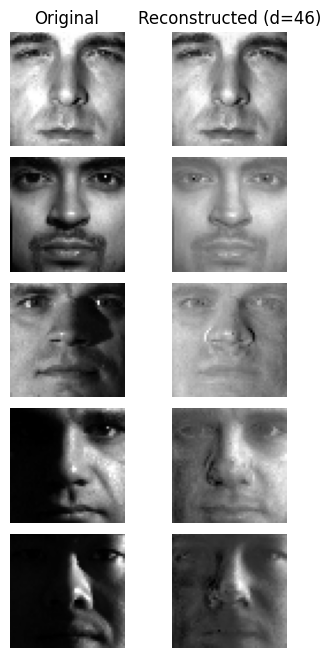

In [ ]:
fig = plt.figure(figsize=(4, 8))

for i, test_set in enumerate(keys):
    ax1 = fig.add_subplot(len(keys), 2, 2 * i + 1)
    ax1.imshow(original_imgs[test_set], cmap='gray')
    ax1.axis('off')
    if i == 0:
        ax1.set_title("Original")

    ax2 = fig.add_subplot(len(keys), 2, 2 * i + 2)
    ax2.imshow(reconstructed_imgs[test_set], cmap='gray')
    ax2.axis('off')
    if i == 0:
        ax2.set_title(f"Reconstructed (d={d})")

plt.subplots_adjust(wspace=0.1, hspace=0.1)
plt.show()

We observe that the reconstruction quality is very high for images of Sets 1 and 2. The quality decreases for Sets 3, 4 and 5, which contain darker images taken under light conditions different from those of Sets 1 and 2.

Question 7 - Using SVD to get top 9 singular vectors:

During PCA we are searching for the orthonormal eigenvectors of the covariance matrix $XX^T$ and their corresponding eigenvalues. Let $W$ be the matrix that has in its columns the orthonormal eigenvectors of $XX^T$. Then we have: $XX^TW=WΛ$, where $Λ$ is the diagonal matrix with the corresponding eigenvalues.


Another way to find the matrix with the orthonormal eigenvectors of $XX^T$ is to use Singural Value Decomposition (SVD). SVD decomposes a matrix $X$ into three matrices: $X=UΣV^T$ where $U,V^T$ are orthogonal matrices and $Σ$ is a diagonal matrix. The columns of $U$ and the columns of $V^T$ are called left singular vectors and right singular vectors respectively. The values in the diagonal of $Σ$ are called singular values.

It can be shown that the matrix $U$ is the eignevector matrix (contains eigenvectors in its columns) of the covariance matrix $XX^T$. In other words $W=U$. Thus, PCA leverages SVD to compute the top k principal components (eigenvectors) by just computing the SVD of $X$. The SVD of $X$ gives us the matrix $U$ which contains the desirable eigenvectors or singular vectors.

We illustrate the top 9 singular vectors we take from SVD and compare them to the top 9 eigenvectors returned by PCA.

In [ ]:
U, S, Vt = np.linalg.svd(X['Set_1'],full_matrices=False)

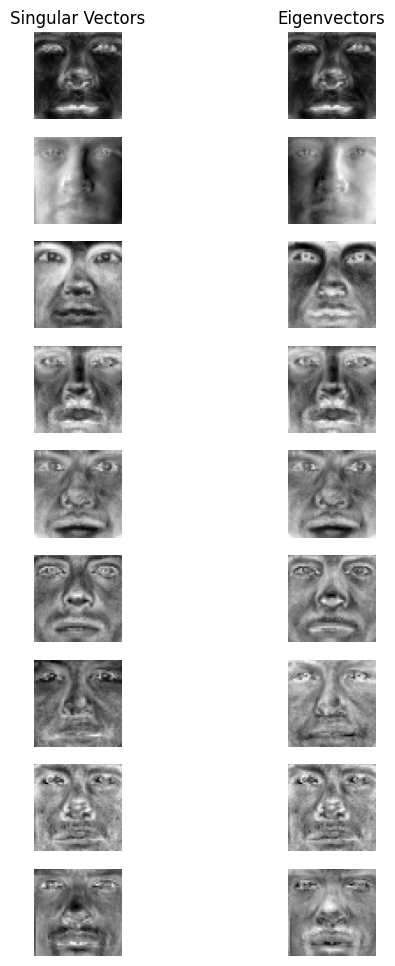

In [ ]:
fig = plt.figure(figsize=(6, 12))
d = 46
for i in range(9):
    ax1 = fig.add_subplot(9, 2, 2 * i + 1)
    ax1.imshow(U[:, i].reshape(50, 50), cmap='gray')
    ax1.axis('off')
    if i == 0:
        ax1.set_title("Singular Vectors")

    ax2 = fig.add_subplot(9, 2, 2 * i + 2)
    ax2.imshow(pca_models[d].top_k_eigenvectors[:,i].reshape(50, 50), cmap='gray')
    ax2.axis('off')
    if i == 0:
        ax2.set_title("Eigenvectors")

plt.subplots_adjust(wspace=0.2, hspace=0.2)
plt.show()

We observe that the top 9 singular vectors returned by SVD capture the same important patters in the images (lighting,nose,eyes), as do the eigenvectors returned by PCA. They are also almost identical to the eigenvectors, as expected from the mathematical analysis given above.